In [365]:
# Perceptron Trick Code

In [366]:
from sklearn.datasets import make_classification

In [367]:
X, y = make_classification(
    n_samples=1000,  # Number of samples
    n_features=2,  # Number of features
    n_classes=2,  # Number of classes (binary)
    n_clusters_per_class=1,  # Number of clusters per class
    n_redundant=0,  # Number of redundant features
    random_state=42,
    class_sep=10,
    hypercube=False,  # Seed for reproducibility
)

In [368]:
import pandas as pd

In [369]:
df = pd.DataFrame(X, columns=["Feature1", "Feature2"])

In [370]:
df["target"] = y

In [371]:
df.corr()

,Feature1,Feature2,target
Feature1,1.000000,0.370665,-0.190710
Feature2,0.370665,1.000000,0.706256
target,-0.190710,0.706256,1.000000


In [372]:
import numpy as np

In [373]:
head = np.ones((y.shape[0], 1))

In [374]:
new_x = np.concat((head, X), axis=1)

In [375]:
import matplotlib.pyplot as plt

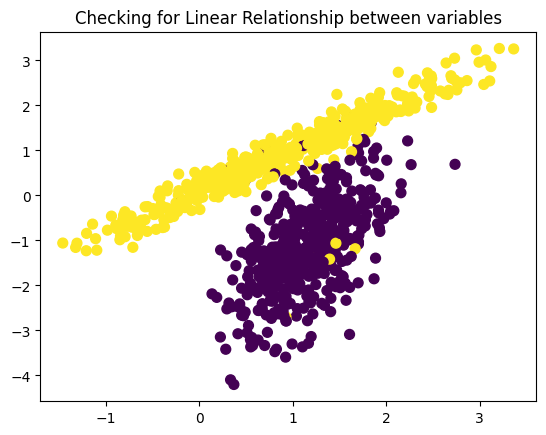

In [376]:
plt.scatter(df["Feature1"], df["Feature2"], s=50, c=df["target"], cmap="viridis")
plt.title("Checking for Linear Relationship between variables")
plt.show()

In [377]:
new_x

array([[ 1.        ,  0.60284474,  0.71606226],
       [ 1.        , -0.2477114 , -0.16599416],
       [ 1.        ,  0.17744322,  0.20832983],
       ...,
       [ 1.        ,  0.93304681, -0.75338888],
       [ 1.        ,  1.22842546, -1.38328801],
       [ 1.        ,  0.8751308 , -1.82808642]], shape=(1000, 3))

In [378]:
weights = np.linspace(0, 1, 3).reshape(-1, 1)

In [379]:
weights

array([[0. ],
       [0.5],
       [1. ]])

In [380]:
predictions = np.random.randint(0, 2, y.shape[0])

In [381]:
import random
from tqdm import tqdm


def Perceptron(X: np.ndarray = X, y: np.ndarray = y, learning_rate=0.01):
    for i in tqdm(range(10000), desc="Updating Initials Weights"):
        row = random.randint(0, y.shape[0] - 1)
        rndm_row = X[row]
        loss = y[row] - predictions[row]
        new_weights = weights.T + learning_rate * (loss * rndm_row)
    return new_weights

In [382]:
weights

array([[0. ],
       [0.5],
       [1. ]])

In [383]:
Perceptron(new_x, y)

Updating Initials Weights: 100%|██████████| 10000/10000 [00:00<00:00, 98032.34it/s]


array([[-0.01      ,  0.48868104,  1.01168045]])

In [384]:
import numpy as np
import random
from tqdm import tqdm


def Perceptron(X: np.ndarray, y: np.ndarray, learning_rate=0.01, max_iterations=10000):
    # Initialize weights with zeros (one weight for each feature plus bias)
    weights = np.zeros(X.shape[1] + 1)

    # Add bias term to X
    X_bias = np.c_[np.ones((X.shape[0], 1)), X]

    for i in tqdm(range(max_iterations), desc="Training Perceptron"):
        # Select random sample
        row = random.randint(0, y.shape[0] - 1)

        # Get random row with bias term
        rndm_row = X_bias[row]

        # Calculate prediction
        prediction = 1 if np.dot(weights, rndm_row) >= 0 else 0

        # Calculate loss
        loss = y[row] - prediction

        # Update weights only if prediction is wrong
        if loss != 0:
            weights = weights + learning_rate * loss * rndm_row

    return weights

In [385]:
final_weights = Perceptron(X, y)

Training Perceptron: 100%|██████████| 10000/10000 [00:00<00:00, 201485.52it/s]


In [386]:
final_weights

array([ 0.02      , -0.04578996,  0.04464656])

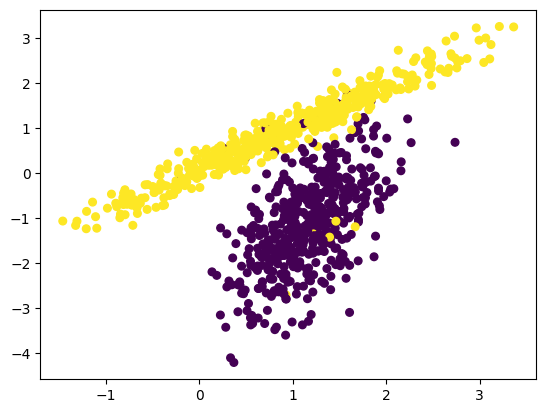

In [387]:
plt.scatter(df["Feature1"], df["Feature2"], s=30, c=df["target"])
plt.show()

In [388]:
def plot_decision_boundary(X, y, weights):
    # Add scatter plot
    plt.figure(figsize=(10, 8))
    plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color="red", label="Class 0")
    plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color="blue", label="Class 1")

    # Calculate decision boundary line
    # From w0 + w1x1 + w2x2 = 0
    # we get x2 = (-w0 - w1x1) / w2
    x1 = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])
    x2 = -(weights[0] + weights[1] * x1) / weights[2]

    # Plot decision boundary
    plt.plot(x1, x2, "g-", label="Decision Boundary")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Perceptron Decision Boundary")
    plt.legend()
    plt.grid(True)
    plt.show()

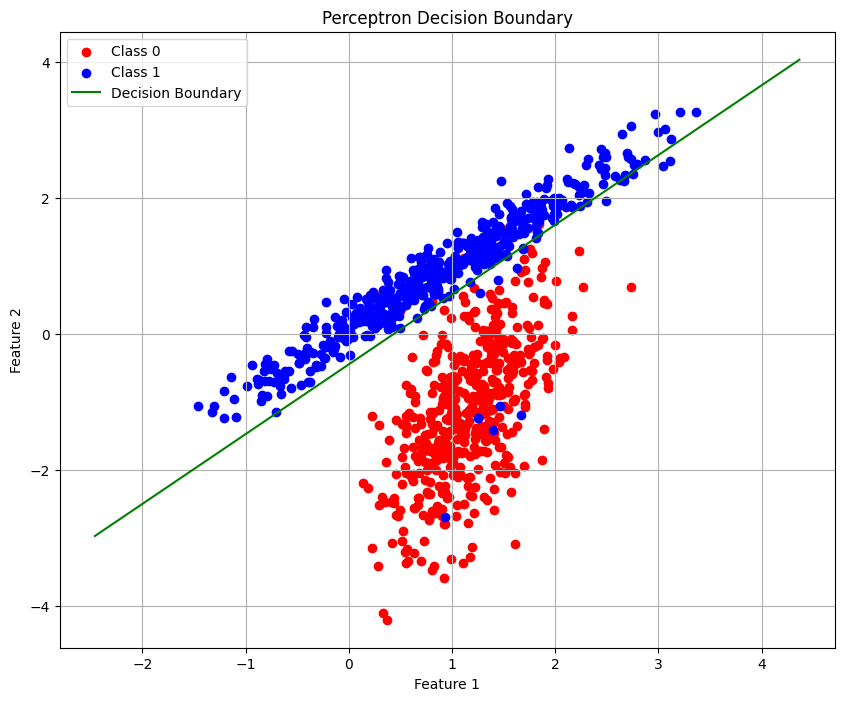

In [389]:
plot_decision_boundary(X, y, final_weights)

Training Perceptron: 100%|██████████| 1000/1000 [00:19<00:00, 52.62it/s]


Maximum epochs reached!

Final accuracy: 98.87%


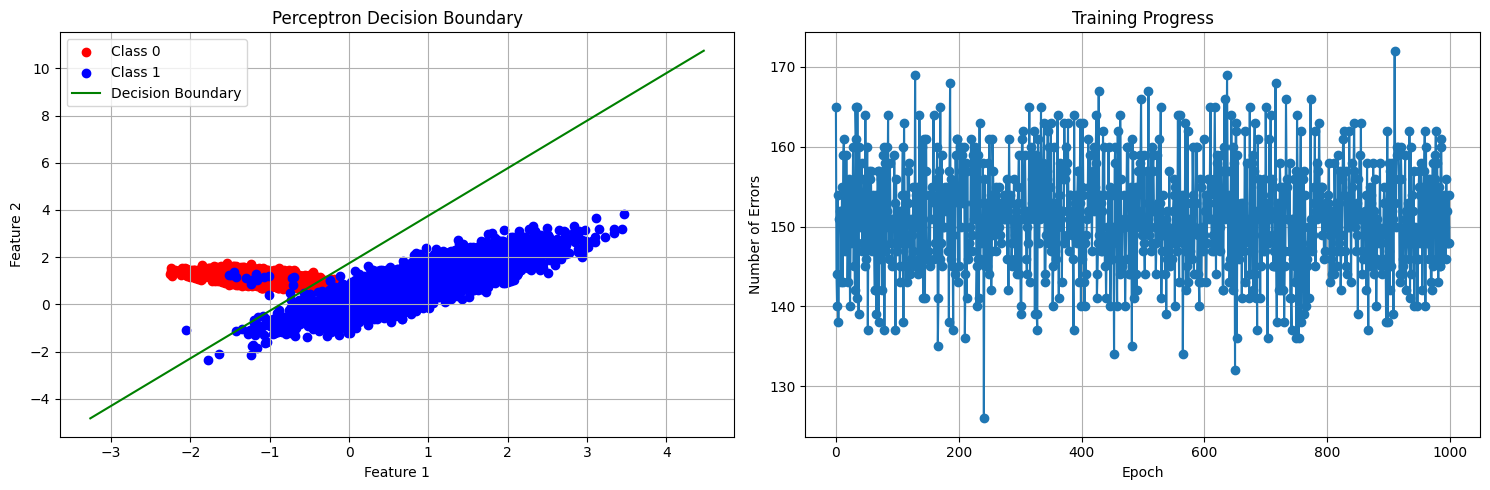

In [398]:
import numpy as np
import random
from tqdm import tqdm


def ImprovedPerceptron(
    X: np.ndarray,
    y: np.ndarray,
    learning_rate=0.01,
    max_epochs=100,
    tol=1e-4,
    shuffle=True,
):
    """
    Improved Perceptron implementation with early stopping and convergence checking.

    Parameters:
    -----------
    X : np.ndarray
        Input features
    y : np.ndarray
        Target labels (0 or 1)
    learning_rate : float
        Learning rate for weight updates
    max_epochs : int
        Maximum number of complete passes through the training data
    tol : float
        Tolerance for convergence (minimum change in weights)
    shuffle : bool
        Whether to shuffle the data in each epoch

    Returns:
    --------
    weights : np.ndarray
        Final weights after training
    n_iter_ : int
        Number of epochs until convergence
    """
    # Add bias term to X
    X_bias = np.c_[np.ones((X.shape[0], 1)), X]

    # Initialize weights with small random values instead of zeros
    weights = np.random.randn(X_bias.shape[1]) * 0.01

    # Keep track of previous weights for convergence check
    prev_weights = np.zeros_like(weights)

    # Create index array for shuffling
    indices = np.arange(X_bias.shape[0])

    # Keep track of errors per epoch
    errors_per_epoch = []

    for epoch in tqdm(range(max_epochs), desc="Training Perceptron"):
        errors = 0

        # Shuffle the training data
        if shuffle:
            np.random.shuffle(indices)
            X_shuffled = X_bias[indices]
            y_shuffled = y[indices]
        else:
            X_shuffled = X_bias
            y_shuffled = y

        # Process each training example
        for i in range(X_shuffled.shape[0]):
            # Calculate prediction
            prediction = 1 if np.dot(weights, X_shuffled[i]) >= 0 else 0

            # Update weights if prediction is wrong
            error = y_shuffled[i] - prediction
            if error != 0:
                weights = weights + learning_rate * error * X_shuffled[i]
                errors += 1

        # Store number of errors in this epoch
        errors_per_epoch.append(errors)

        # Check for convergence
        weight_diff = np.sum(np.abs(weights - prev_weights))
        if weight_diff < tol and errors == 0:
            print(f"Converged after {epoch + 1} epochs!")
            return weights, epoch + 1, errors_per_epoch

        # Update previous weights
        prev_weights = weights.copy()

        # Early stopping if perfect classification
        if errors == 0:
            print(f"Perfect classification achieved after {epoch + 1} epochs!")
            return weights, epoch + 1, errors_per_epoch

    print("Maximum epochs reached!")
    return weights, max_epochs, errors_per_epoch


# Function to evaluate the perceptron
def evaluate_perceptron(X, y, weights):
    """
    Evaluate the perceptron's performance on given data.

    Returns accuracy and predictions.
    """
    X_bias = np.c_[np.ones((X.shape[0], 1)), X]
    predictions = (np.dot(X_bias, weights) >= 0).astype(int)
    accuracy = (predictions == y).mean()
    return accuracy, predictions


# Function to plot the decision boundary with additional information
def plot_decision_boundary_improved(X, y, weights, errors_per_epoch=None):
    """
    Plot the decision boundary and training progress.
    """
    plt.figure(figsize=(15, 5))

    # Plot decision boundary
    plt.subplot(121)
    plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color="red", label="Class 0")
    plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color="blue", label="Class 1")

    # Calculate decision boundary line
    x1 = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])
    x2 = -(weights[0] + weights[1] * x1) / weights[2]

    plt.plot(x1, x2, "g-", label="Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Perceptron Decision Boundary")
    plt.legend()
    plt.grid(True)

    # Plot training progress if available
    if errors_per_epoch is not None:
        plt.subplot(122)
        plt.plot(errors_per_epoch, "-o")
        plt.xlabel("Epoch")
        plt.ylabel("Number of Errors")
        plt.title("Training Progress")
        plt.grid(True)

    plt.tight_layout()
    plt.show()


# Example usage:
# Generate synthetic dataset
X, y = make_classification(
    n_samples=10000,
    n_features=2,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=10,
    n_redundant=0,
    random_state=42,
    hypercube=False,
)

# Train the improved perceptron
trained_weights, n_epochs, errors_history = ImprovedPerceptron(
    X, y, learning_rate=0.01, max_epochs=1000, tol=1e-4
)

# Evaluate the model
accuracy, predictions = evaluate_perceptron(X, y, trained_weights)
print(f"\nFinal accuracy: {accuracy:.2%}")

# Plot the results
plot_decision_boundary_improved(X, y, trained_weights, errors_history)

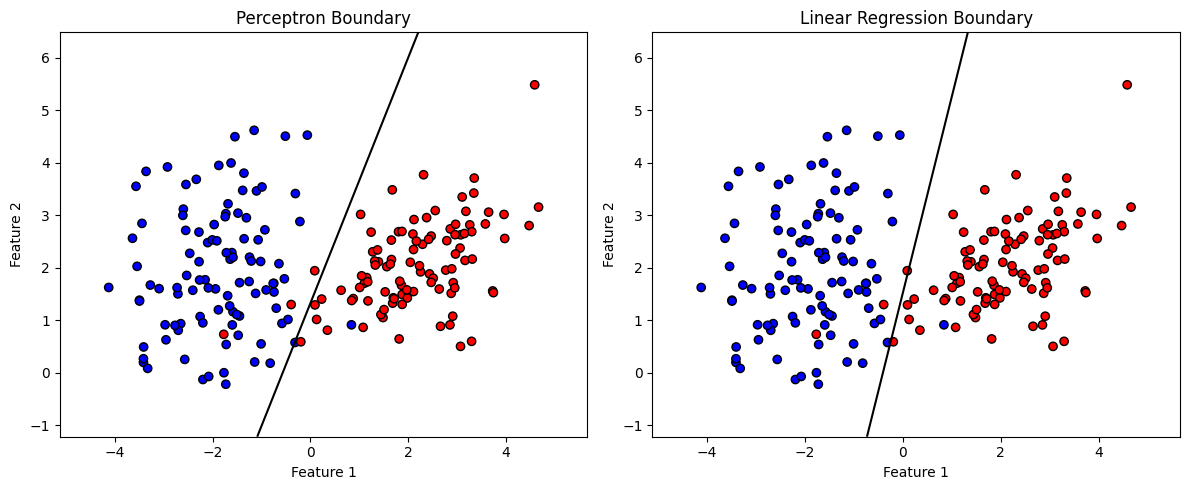

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron, LinearRegression
from sklearn.datasets import make_classification

# 1. Create a 2D linearly separable dataset
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0,
                           n_informative=2, n_clusters_per_class=1,
                           class_sep=2.0, random_state=42)
y = np.where(y == 0, -1, 1)  # Perceptron expects labels -1 or +1

# 2. Fit a Perceptron
per = Perceptron(max_iter=1000, eta0=0.1, random_state=42)
per.fit(X, y)

# 3. Fit a Linear Regression and use it as a classifier
lin = LinearRegression()
lin.fit(X, y)
y_lin = np.where(lin.predict(X) > 0, 1, -1)

# 4. Plot data and decision boundaries
xx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 200)
yy = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 200)
XX, YY = np.meshgrid(xx, yy)
grid = np.c_[XX.ravel(), YY.ravel()]

# Decision values
Z_per = per.decision_function(grid).reshape(XX.shape)
Z_lin = lin.predict(grid).reshape(XX.shape)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

for ax, Z, title in zip(axs, [Z_per, Z_lin],
                        ["Perceptron Boundary", "Linear Regression Boundary"]):
    ax.contour(XX, YY, Z, levels=[0], colors='k')
    ax.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k')
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')

plt.tight_layout()
plt.show()

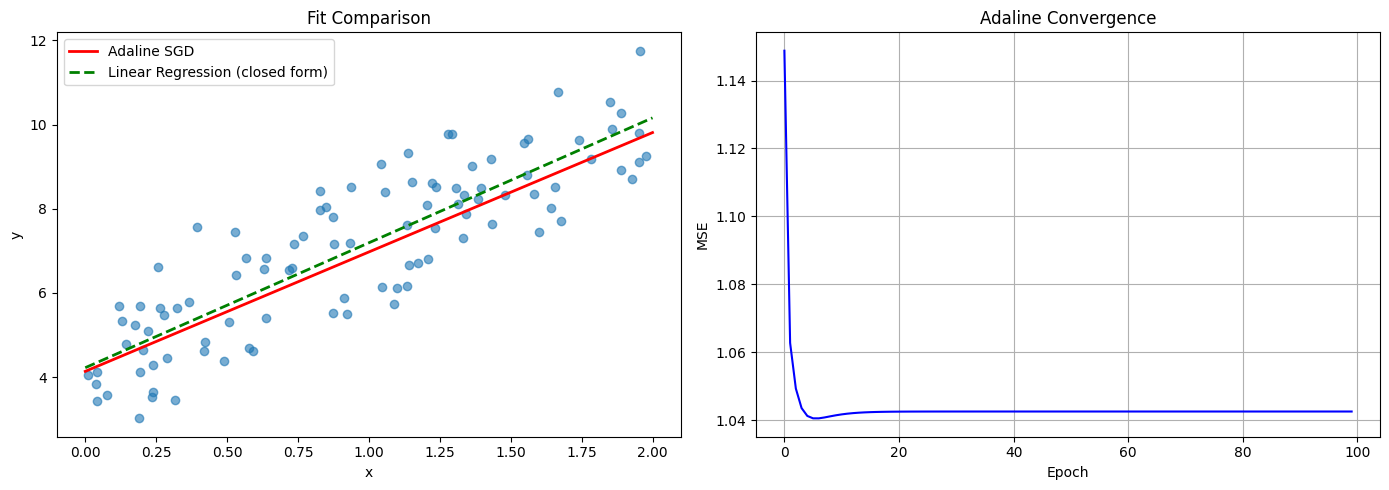

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate synthetic linear data with noise
np.random.seed(0)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X[:, 0] + np.random.randn(100)  # y = 4 + 3x + noise

# Add bias term
X_b = np.c_[np.ones((100, 1)), X]

# 2. Perceptron-like regression: Adaline using SGD (MSE minimization)
eta = 0.01
n_epochs = 100
theta = np.random.randn(2)
mse_hist = []

for epoch in range(n_epochs):
    for i in range(len(X_b)):
        xi, yi = X_b[i], y[i]
        error = xi.dot(theta) - yi
        theta -= eta * 2 * error * xi
    mse_hist.append(np.mean((X_b.dot(theta) - y)**2))

theta_sgd = theta.copy()

# 3. Closed-form Linear Regression
theta_closed = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

# 4. Plot results
plt.figure(figsize=(14, 5))

# a) Regression lines
plt.subplot(1, 2, 1)
plt.scatter(X, y, alpha=0.6)
x0 = np.array([[0], [2]])
x0_b = np.c_[np.ones((2,1)), x0]
y_sgd = x0_b.dot(theta_sgd)
y_closed = x0_b.dot(theta_closed)
plt.plot(x0, y_sgd, "r-", linewidth=2, label="Adaline SGD")
plt.plot(x0, y_closed, "g--", linewidth=2, label="Linear Regression (closed form)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Fit Comparison")
plt.legend()

# b) MSE convergence
plt.subplot(1, 2, 2)
plt.plot(mse_hist, "b-")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Adaline Convergence")
plt.grid(True)

plt.tight_layout()
plt.show()

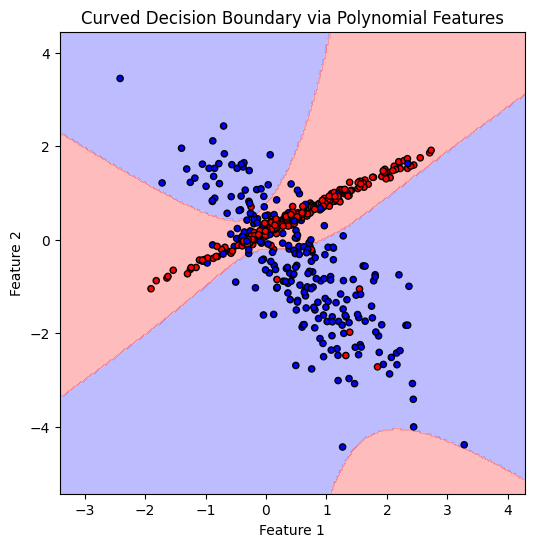

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression

# 1. Create a 2D dataset that is NOT linearly separable
X, y = make_classification(n_samples=500, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, class_sep=0.5, flip_y=0.1,
                           random_state=42)

# 2. Transform features to polynomial (degree=3 for curved boundary)
poly = PolynomialFeatures(degree=4, include_bias=True)
X_poly = poly.fit_transform(X)

# 3. Fit logistic regression on polynomial features
clf = LogisticRegression(max_iter=10000)
clf.fit(X_poly, y)

# 4. Visualization grid
xx = np.linspace(X[:,0].min() - 1, X[:,0].max() + 1, 300)
yy = np.linspace(X[:,1].min() - 1, X[:,1].max() + 1, 300)
XX, YY = np.meshgrid(xx, yy)
grid = np.c_[XX.ravel(), YY.ravel()]
Z = clf.predict(poly.transform(grid)).reshape(XX.shape)

# 5. Plot
plt.figure(figsize=(6, 6))
plt.contourf(XX, YY, Z, alpha=0.3, cmap='bwr')
plt.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k', s=20)
plt.title("Curved Decision Boundary via Polynomial Features")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

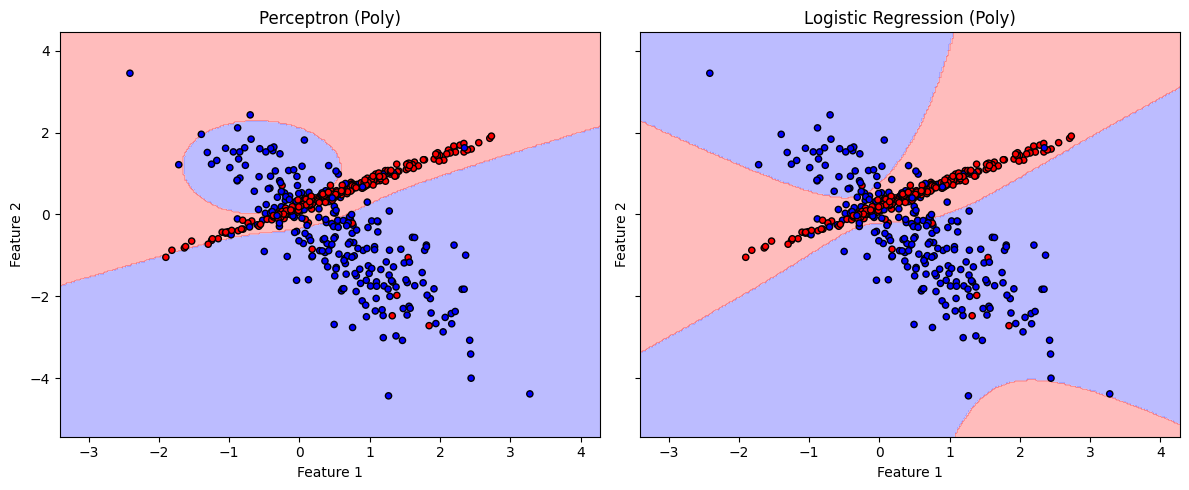

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.pipeline import make_pipeline

# 1. Generate a non-linearly separable dataset
X, y = make_classification(n_samples=500, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, class_sep=0.5, flip_y=0.1,
                           random_state=42)

# 2. Build pipelines with polynomial features (degree 3)
degree = 3
perceptron_clf = make_pipeline(
    PolynomialFeatures(degree, include_bias=True),
    Perceptron(max_iter=1000, tol=1e-3, random_state=42)
)
logreg_clf = make_pipeline(
    PolynomialFeatures(degree, include_bias=True),
    LogisticRegression(max_iter=10000)
)

# 3. Fit both models
perceptron_clf.fit(X, y)
logreg_clf.fit(X, y)

# 4. Meshgrid for visualization
xx = np.linspace(X[:,0].min() - 1, X[:,0].max() + 1, 300)
yy = np.linspace(X[:,1].min() - 1, X[:,1].max() + 1, 300)
XX, YY = np.meshgrid(xx, yy)
grid = np.c_[XX.ravel(), YY.ravel()]

# Predictions
Z_per = perceptron_clf.predict(grid).reshape(XX.shape)
Z_log = logreg_clf.predict(grid).reshape(XX.shape)

# 5. Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, Z, title in zip(axes,
                        [Z_per, Z_log],
                        ["Perceptron (Poly)", "Logistic Regression (Poly)"]):
    ax.contourf(XX, YY, Z, alpha=0.3, cmap='bwr')
    ax.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k', s=20)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

Logistic Best Params: {'clf__C': 10, 'poly__degree': 4}
Logistic CV Best Score: 0.8459999999999999
Perceptron Best Degree: {'poly__degree': 3}
Perceptron CV Best Score: 0.8039999999999999


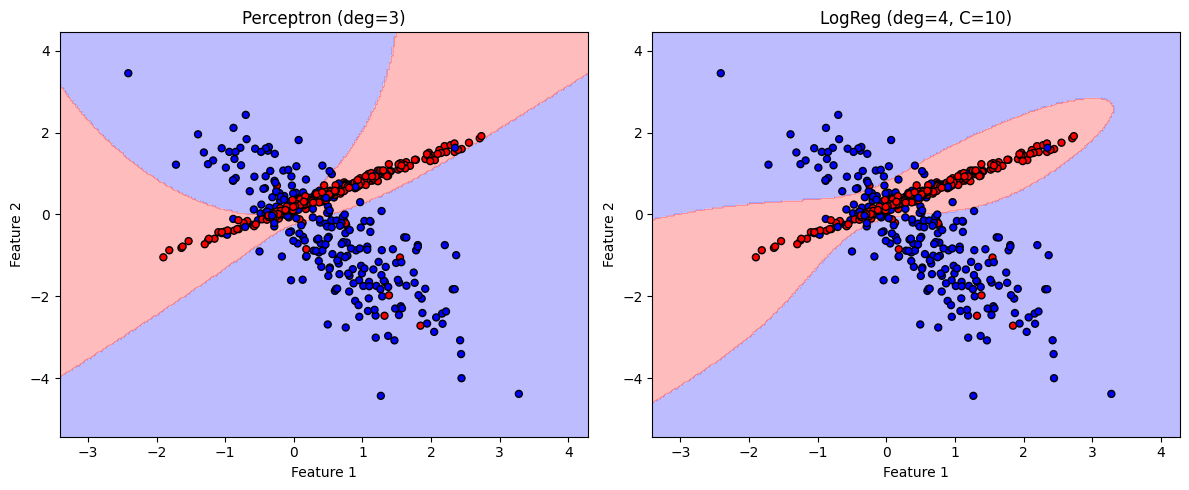

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# 1. Generate non-linear data
X, y = make_classification(n_samples=500, n_features=2,
                           n_redundant=0, n_clusters_per_class=1,
                           class_sep=0.5, flip_y=0.1, random_state=42)

# 2. Define pipelines
pipe_per = Pipeline([
    ('poly', PolynomialFeatures()),
    ('scale', StandardScaler()),
    ('clf', Perceptron(max_iter=1000, tol=1e-3))
])
pipe_log = Pipeline([
    ('poly', PolynomialFeatures()),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=5000))
])

# 3. Hyperparameter grid
param_grid = {
    'poly__degree': [1, 2, 3, 4],
    'clf__C': [0.01, 0.1, 1, 10]  # Only relevant for LogisticRegression
}

# GridSearchCV for Logistic Regression
grid_log = GridSearchCV(pipe_log, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_log.fit(X, y)
print("Logistic Best Params:", grid_log.best_params_)
print("Logistic CV Best Score:", grid_log.best_score_)

# GridSearchCV for Perceptron (ignores C)
grid_per = GridSearchCV(pipe_per, {'poly__degree': [1, 2, 3, 4]}, cv=5, scoring='accuracy', n_jobs=-1)
grid_per.fit(X, y)
print("Perceptron Best Degree:", grid_per.best_params_)
print("Perceptron CV Best Score:", grid_per.best_score_)

# 4. Visualize both best models
xx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300)
yy = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300)
XX, YY = np.meshgrid(xx, yy)
grid = np.c_[XX.ravel(), YY.ravel()]

Z_log = grid_log.predict(grid).reshape(XX.shape)
Z_per = grid_per.predict(grid).reshape(XX.shape)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, Z, title in zip(axs,
                        [Z_per, Z_log],
                        [f"Perceptron (deg={grid_per.best_params_['poly__degree']})",
                         f"LogReg (deg={grid_log.best_params_['poly__degree']}, C={grid_log.best_params_['clf__C']})"]):
    ax.contourf(XX, YY, Z, alpha=0.3, cmap='bwr')
    ax.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k', s=25)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

In [9]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.datasets import make_classification
# from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# from sklearn.linear_model import Perceptron, LogisticRegression
# from sklearn.pipeline import Pipeline
# from sklearn.model_selection import GridSearchCV
# import warnings
# warnings.filterwarnings('ignore')

# # 1. Generate non-linear dataset
# X, y = make_classification(n_samples=500, n_features=2,
#                            n_redundant=0, n_clusters_per_class=1,
#                            class_sep=0.5, flip_y=0.1, random_state=42)

# # 2. Define pipelines
# pipe_per = Pipeline([
#     ('poly', PolynomialFeatures()),
#     ('scale', StandardScaler()),
#     ('clf', Perceptron(random_state=42))
# ])
# pipe_log = Pipeline([
#     ('poly', PolynomialFeatures()),
#     ('scale', StandardScaler()),
#     ('clf', LogisticRegression(max_iter=10000))
# ])

# # 3. Set hyperparameter grids
# param_grid_per = {
#     'poly__degree': [1, 2, 3, 4,5,6],
#     'clf__penalty': [None, 'l2', 'l1'],
#     'clf__alpha': [0.0001, 0.001, 0.01],  # perceptron doesn't support alpha directly, but using sklearn’s version allows alpha
#     'clf__eta0': [0.001, 0.01, 0.1]
# }
# param_grid_log = {
#     'poly__degree': [1, 2, 3, 4,5,6],
#     'clf__penalty': ['l2', 'l1', None],
#     'clf__C': np.logspace(-3, 3, 7),
#     'clf__solver': ['lbfgs', 'liblinear', 'saga']  # different solvers support different penalties
# }

# # 4. Perform Grid Search with CV
# grid_per = GridSearchCV(pipe_per, param_grid_per, cv=5, scoring='accuracy', n_jobs=-1)
# grid_log = GridSearchCV(pipe_log, param_grid_log, cv=5, scoring='accuracy', n_jobs=-1)

# grid_per.fit(X, y)
# grid_log.fit(X, y)

# print("🎯 Perceptron best params:", grid_per.best_params_)
# print("🏆 Perceptron CV acc:", grid_per.best_score_)
# print("\n🎯 Logistic best params:", grid_log.best_params_)
# print("🏆 Logistic CV acc:", grid_log.best_score_)

# # 5. Visualize decision boundaries
# xx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300)
# yy = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300)
# XX, YY = np.meshgrid(xx, yy)
# grid = np.c_[XX.ravel(), YY.ravel()]

# Z_per = grid_per.predict(grid).reshape(XX.shape)
# Z_log = grid_log.predict(grid).reshape(XX.shape)

# fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# for ax, Z, title in zip(
#     axs, [Z_per, Z_log],
#     [f"Perceptron (deg={grid_per.best_params_['poly__degree']}, pen={grid_per.best_params_['clf__penalty']}, η={grid_per.best_params_['clf__eta0']})",
#      f"Logistic (deg={grid_log.best_params_['poly__degree']}, pen={grid_log.best_params_['clf__penalty']}, C={grid_log.best_params_['clf__C']}, solver={grid_log.best_params_['clf__solver']})"]
# ):
#     ax.contourf(XX, YY, Z, alpha=0.3, cmap='bwr')
#     ax.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k', s=25)
#     ax.set_title(title)
#     ax.set_xlabel("Feature 1")
#     ax.set_ylabel("Feature 2")

# plt.tight_layout()
# plt.show()